<a href="https://colab.research.google.com/github/ananthanss9775-cmd/Sex-prediction-of-Laysan-Albatross/blob/main/Prediction_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [8]:
data = pd.read_csv('/content/drive/MyDrive/DSA COURSE/HACKATHON /SEX PREDICTION ML/train.csv')

In [9]:
print(data)

          id sexo  longitudCraneo  ...  mediaEnvergadura  envergadura  peso
0   0J4_2016    H          174.18  ...             104.2        208.4  2.38
1   A68_2016    H          171.12  ...             102.2        204.4  2.14
2   E55_2015    H          174.69  ...             105.2        210.4  2.50
3   7C7_2016    M          182.25  ...             107.6        215.2  2.83
4   2C0_2018    H          173.70  ...             103.7        207.4  2.73
..       ...  ...             ...  ...               ...          ...   ...
89  H50_2017    H          168.18  ...             105.9        211.8  2.73
90  3C0_2015    H          173.95  ...             105.9        211.8  2.65
91  A62_2016    M          181.01  ...             105.4        210.8  2.55
92  H24_2015    M          181.51  ...             107.4        214.8  3.10
93  1J4_2018    H          170.56  ...             102.6        205.2  2.67

[94 rows x 14 columns]


In [10]:
data.head()

,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73


In [12]:
data.isnull().sum()

,0
id,0
sexo,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0


In [13]:
data.duplicated().sum()

np.int64(0)

In [14]:
data.describe()

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
count,94.000000,94.000000,94.000000,94.000000,94.000000,94.000000,94.00000,94.000000,94.000000,94.000000,94.000000,93.000000
mean,176.580106,110.130426,82.936383,52.687553,32.535000,25.425319,90.88766,51.667021,96.259043,104.765213,209.530426,2.624516
std,5.443278,4.028920,3.187515,2.226749,1.383418,1.439065,2.85098,1.185340,2.187660,2.486498,4.972997,0.315968
min,165.580000,102.710000,74.820000,46.500000,29.340000,21.480000,84.04000,48.700000,88.900000,99.300000,198.600000,2.030000
25%,172.187500,106.835000,80.217500,51.207500,31.605000,24.500000,88.66000,51.000000,94.725000,103.175000,206.350000,2.400000
50%,176.915000,110.070000,83.325000,52.475000,32.605000,25.480000,91.03500,51.600000,96.500000,104.950000,209.900000,2.600000
75%,180.525000,113.252500,85.425000,54.347500,33.460000,26.372500,92.57000,52.475000,97.875000,106.550000,213.100000,2.830000
max,191.210000,119.480000,90.680000,58.360000,35.500000,28.700000,99.69000,54.700000,101.300000,112.200000,224.400000,3.530000


In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                94 non-null     object 
 1   sexo              94 non-null     object 
 2   longitudCraneo    94 non-null     float64
 3   longitudPico      94 non-null     float64
 4   longitudNarina    94 non-null     float64
 5   anchoCraneo       94 non-null     float64
 6   altoPico          94 non-null     float64
 7   anchoPico         94 non-null     float64
 8   tarso             94 non-null     float64
 9   longAlaCerrada    94 non-null     float64
 10  longAlaAbierta    94 non-null     float64
 11  mediaEnvergadura  94 non-null     float64
 12  envergadura       94 non-null     float64
 13  peso              93 non-null     float64
dtypes: float64(12), object(2)
memory usage: 10.4+ KB


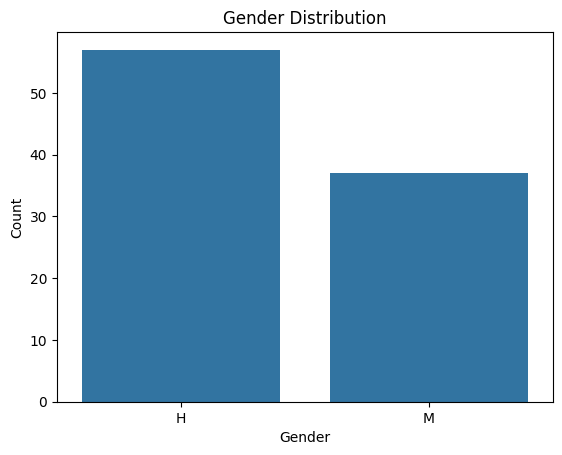

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=data, x='sexo')

plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

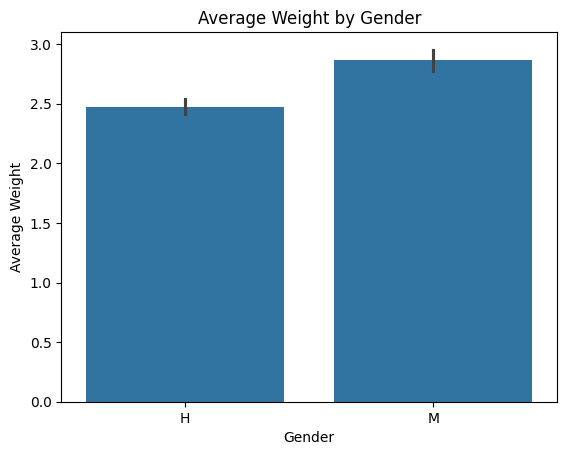

In [18]:
sns.barplot(data=data, x='sexo', y='peso')

plt.title('Average Weight by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Weight')
plt.show()

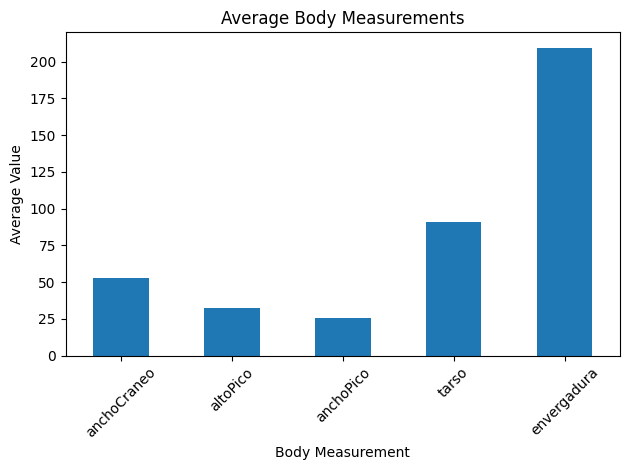

In [19]:
columns = [
    'anchoCraneo',
    'altoPico',
    'anchoPico',
    'tarso',
    'envergadura'
]

data[columns].mean().plot(kind='bar')

plt.title('Average Body Measurements')
plt.xlabel('Body Measurement')
plt.ylabel('Average Value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
data['sexo'].value_counts()

,count
sexo,
H,57
M,37


In [25]:
data.groupby('sexo')['peso'].mean()

,peso
sexo,
H,2.473509
M,2.863611


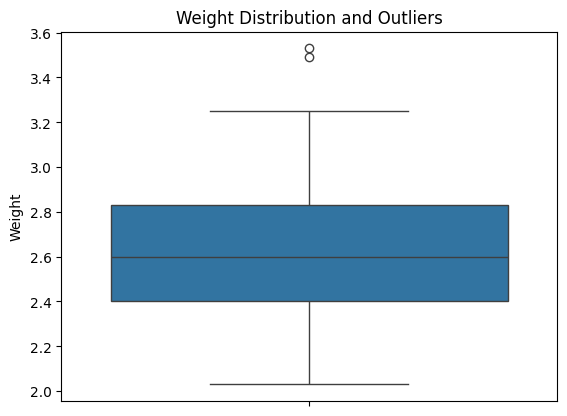

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=data, y='peso')

plt.title('Weight Distribution and Outliers')
plt.ylabel('Weight')
plt.show()

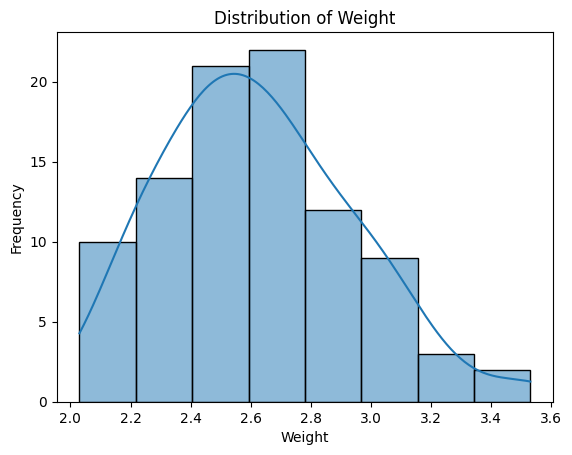

In [27]:
sns.histplot(data=data, x='peso', kde=True)

plt.title('Distribution of Weight')
plt.xlabel('Weight')
plt.ylabel('Frequency')
plt.show()

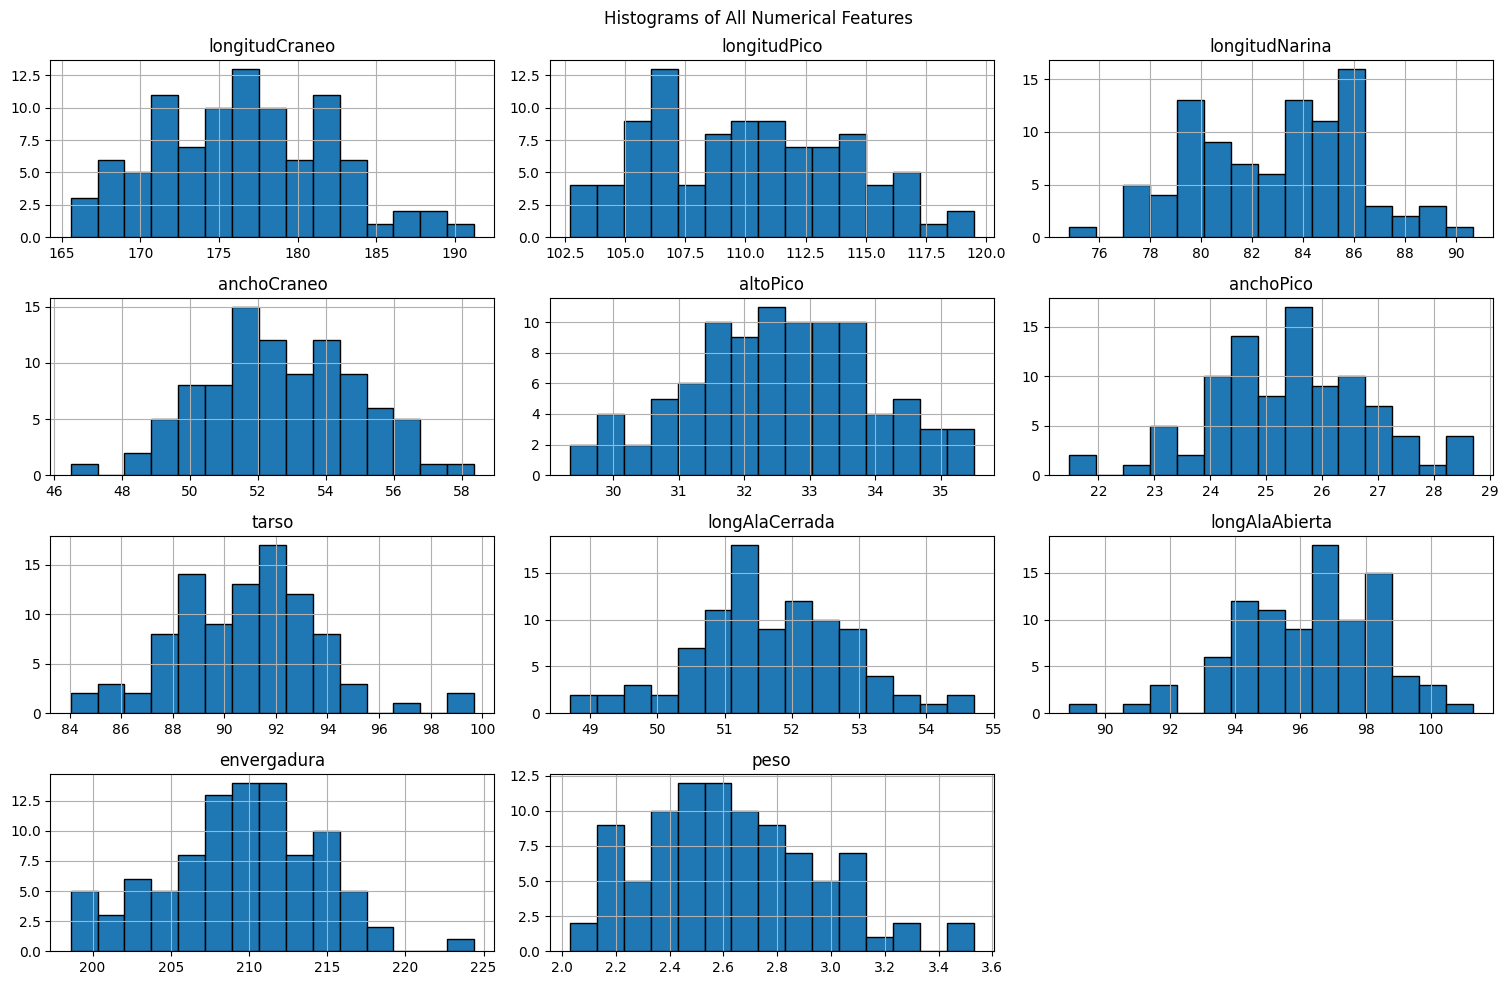

In [41]:
num_cols = data.select_dtypes(include='number').columns
data[num_cols].hist(figsize=(15, 10), bins=15, edgecolor="black")
plt.suptitle("Histograms of All Numerical Features")
plt.tight_layout()
plt.show()

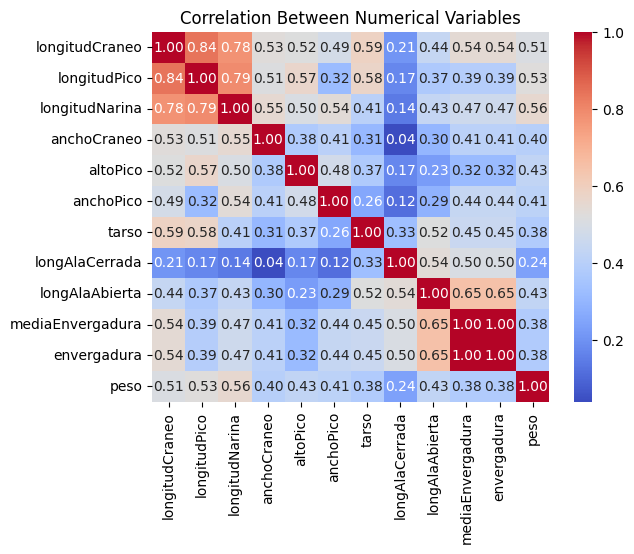

In [28]:
numeric_data = data.select_dtypes(include='number').drop(
    columns=['id'], errors='ignore'
)

correlation = numeric_data.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numerical Variables')
plt.show()

To check the correlation automattically from the heat map

In [29]:
import numpy as np

corr = numeric_data.corr()

# Keep only the upper triangle, excluding the diagonal
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

# Sort correlations from strongest to weakest by absolute value
strongest = upper.abs().stack().sort_values(ascending=False)

print(strongest.head(10))

mediaEnvergadura  envergadura         1.000000
longitudCraneo    longitudPico        0.840354
longitudPico      longitudNarina      0.793306
longitudCraneo    longitudNarina      0.776635
longAlaAbierta    envergadura         0.647892
                  mediaEnvergadura    0.647892
longitudCraneo    tarso               0.586269
longitudPico      tarso               0.575282
                  altoPico            0.568365
longitudNarina    peso                0.556491
dtype: float64


In [30]:
# Keep only the upper triangle to avoid duplicate pairs
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

negative_pairs = upper.stack()
negative_pairs = negative_pairs[negative_pairs < 0]
negative_pairs = negative_pairs.sort_values()

print(negative_pairs)

Series([], dtype: float64)


In [31]:
data[['mediaEnvergadura', 'envergadura']].head(10)

,mediaEnvergadura,envergadura
0,104.20,208.40
1,102.20,204.40
2,105.20,210.40
3,107.60,215.20
4,103.70,207.40
5,106.00,212.00
6,103.70,207.40
7,99.77,199.54
8,107.50,215.00
9,105.00,210.00


In [32]:
(data['envergadura'] == 2 * data['mediaEnvergadura']).all()

np.True_

In [33]:
data = data.drop(columns=['mediaEnvergadura','id'])

In [34]:
corr = data.select_dtypes(include='number').drop(
    columns=['id'], errors='ignore'
).corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

weakest = upper.stack().sort_values(
    key=abs,
    ascending=True
)

print(weakest.head(10))

anchoCraneo     longAlaCerrada    0.039546
anchoPico       longAlaCerrada    0.117352
longitudNarina  longAlaCerrada    0.143903
altoPico        longAlaCerrada    0.173495
longitudPico    longAlaCerrada    0.173829
longitudCraneo  longAlaCerrada    0.205871
altoPico        longAlaAbierta    0.226932
longAlaCerrada  peso              0.239133
anchoPico       tarso             0.256359
                longAlaAbierta    0.287197
dtype: float64


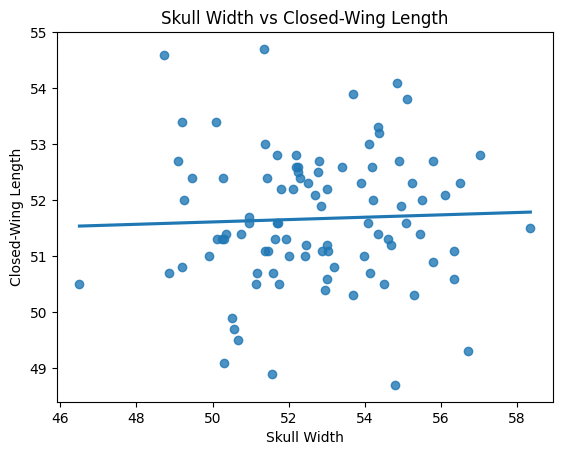

In [35]:
sns.regplot(
    data=data,
    x='anchoCraneo',
    y='longAlaCerrada',
    ci=None
)

plt.title('Skull Width vs Closed-Wing Length')
plt.xlabel('Skull Width')
plt.ylabel('Closed-Wing Length')
plt.show()

In [38]:


numeric_data = data.select_dtypes(include='number').drop(
    columns=['id'], errors='ignore'
)

for col in numeric_data.columns:
    Q1 = numeric_data[col].quantile(0.25)
    Q3 = numeric_data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = numeric_data[
        (numeric_data[col] < lower) |
        (numeric_data[col] > upper)
    ][col]

    print(f"{col}: {len(outliers)} potential outliers")

longitudCraneo: 0 potential outliers
longitudPico: 0 potential outliers
longitudNarina: 0 potential outliers
anchoCraneo: 0 potential outliers
altoPico: 0 potential outliers
anchoPico: 2 potential outliers
tarso: 2 potential outliers
longAlaCerrada: 2 potential outliers
longAlaAbierta: 1 potential outliers
envergadura: 1 potential outliers
peso: 2 potential outliers


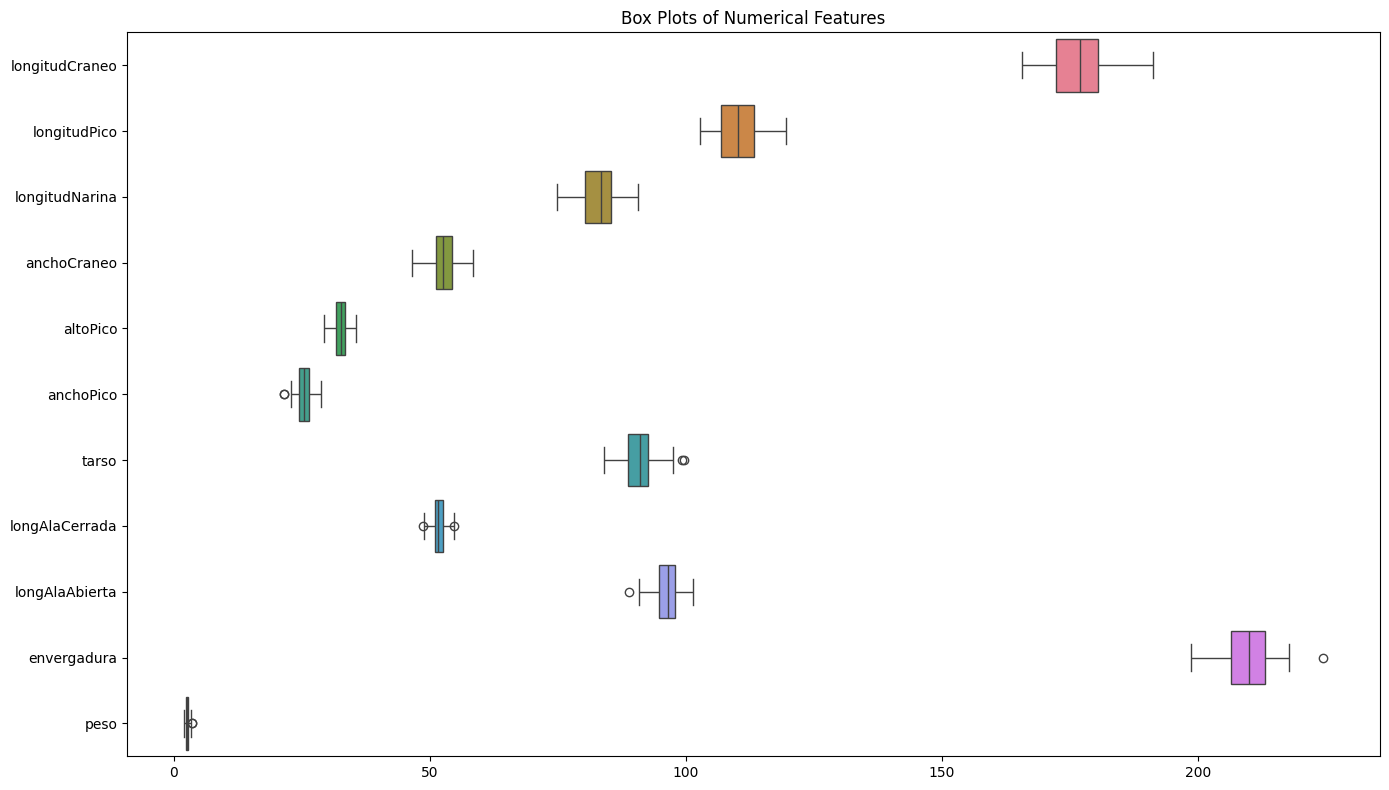

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))

sns.boxplot(data=numeric_data, orient="h")

plt.title("Box Plots of Numerical Features")
plt.tight_layout()
plt.show()

In [42]:
data.groupby('sexo').mean(numeric_only=True).drop(
    columns=['id'], errors='ignore'
).round(2)

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,envergadura,peso
sexo,,,,,,,,,,,
H,173.54,107.77,81.33,51.77,31.89,25.00,89.68,51.50,95.60,207.88,2.47
M,181.26,113.76,85.41,54.10,33.52,26.08,92.75,51.92,97.27,212.08,2.86


In [43]:
# Target variable
y = data['sexo']

# Input features
X = data.drop(columns=['sexo'])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (94, 11)
Target shape: (94,)

Target distribution:
sexo
H    57
M    37
Name: count, dtype: int64

Feature columns:
['longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta', 'envergadura', 'peso']


In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (75, 11)
Testing features: (19, 11)

Training target distribution:
sexo
H    45
M    30
Name: count, dtype: int64

Testing target distribution:
sexo
H    12
M     7
Name: count, dtype: int64


In [47]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [48]:
print(X_train.isnull().sum())

longitudCraneo    0
longitudPico      0
longitudNarina    0
anchoCraneo       0
altoPico          0
anchoPico         0
tarso             0
longAlaCerrada    0
longAlaAbierta    0
envergadura       0
peso              1
dtype: int64


In [49]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(random_state=42)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8947368421052632

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



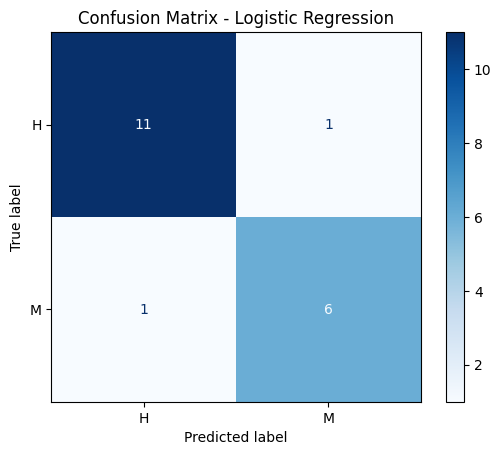

In [50]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=['H', 'M'],
    cmap='Blues'
)

plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [51]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    )
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.8421052631578947

Classification Report:
              precision    recall  f1-score   support

           H       0.85      0.92      0.88        12
           M       0.83      0.71      0.77         7

    accuracy                           0.84        19
   macro avg       0.84      0.82      0.82        19
weighted avg       0.84      0.84      0.84        19



In [55]:
import joblib

joblib.dump(model, 'bird_sex_classifier.pkl')

print("Model saved successfully!")

Model saved successfully!


IMPORTING TEST DATA

In [56]:
test_data = pd.read_csv('/content/drive/MyDrive/DSA COURSE/HACKATHON /SEX PREDICTION ML/test.csv')
submission = pd.read_csv('/content/drive/MyDrive/DSA COURSE/HACKATHON /SEX PREDICTION ML/sample_submission.csv')

print("Test file:")
print(test_data.head())
print(test_data.columns.tolist())

print("\nSubmission file:")
print(submission.head())
print(submission.columns.tolist())

Test file:
         id  longitudCraneo  longitudPico  ...  mediaEnvergadura  envergadura  peso
0  A70_2018          183.57        117.18  ...             104.4        208.8  3.35
1  5C9_2018          166.60        105.05  ...             101.4        202.8  2.43
2  5E1_2018          175.53        111.23  ...             103.4        206.8  2.99
3  C58_2018          187.85        116.90  ...             107.6        215.2  3.55
4  5E2_2018          182.67        116.40  ...             110.1        220.2  3.06

[5 rows x 13 columns]
['id', 'longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta', 'mediaEnvergadura', 'envergadura', 'peso']

Submission file:
     id sexo
0  id_1    M
1  id_2    H
2  id_3    M
['id', 'sexo']


In [58]:
# Features used during model training
feature_columns = [
    'longitudCraneo',
    'longitudPico',
    'longitudNarina',
    'anchoCraneo',
    'altoPico',
    'anchoPico',
    'tarso',
    'longAlaCerrada',
    'longAlaAbierta',
    'envergadura',
    'peso'
]

# Prepare test data in the same format as training data
X_new = test_data[feature_columns].copy()

# Predict bird sex
predictions = model.predict(X_new)

# Create the submission DataFrame using the IDs from the test set to match the length of predictions (41)
submission_df = pd.DataFrame({
    'id': test_data['id'],
    'sexo': predictions
})

# Save the final submission
submission_df.to_csv('submission_completed.csv', index=False)

# Verify the output
print(submission_df.head())
print("\nSubmission shape:", submission_df.shape)
print("\nPredicted classes:")
print(submission_df['sexo'].value_counts())

         id sexo
0  A70_2018    M
1  5C9_2018    H
2  5E1_2018    M
3  C58_2018    M
4  5E2_2018    M

Submission shape: (41, 2)

Predicted classes:
sexo
H    21
M    20
Name: count, dtype: int64


In [59]:
print("Rows in test file:", len(test_data))
print("Rows in submission:", len(submission))

print("Missing values:")
print(submission.isnull().sum())

print("Duplicate IDs:", submission['id'].duplicated().sum())
print("Classes:", submission['sexo'].unique())

Rows in test file: 41
Rows in submission: 3
Missing values:
id      0
sexo    0
dtype: int64
Duplicate IDs: 0
Classes: ['M' 'H']


In [60]:
check = pd.read_csv('submission_completed.csv')
print(check.head())
print(check.shape)

         id sexo
0  A70_2018    M
1  5C9_2018    H
2  5E1_2018    M
3  C58_2018    M
4  5E2_2018    M
(41, 2)


In [61]:
from google.colab import files
files.download('submission_completed.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>